# 04 — Identifiability, excitation design and uncertainty

Notebook 03 showed that the targets have no hidden discrete structure, and the diagnostics showed
that an 8 h curve only partly determines them. This notebook turns that limit into results:

1. **Point accuracy** of the final models (TCN + attention, full training set): MSE loss vs
   Gaussian β-NLL loss (which also predicts a variance per target).
2. **Which tests are informative?** Error as a function of the excitation (regime, PRBS duty
   cycle and switching time): the protocol-design view.
3. **Uncertainty**: are the predicted standard deviations calibrated and informative, and
   conformal intervals with guaranteed coverage.
4. **Identifiability**: which *combinations* of targets the learned representation determines
   (canonical correlation analysis between the model's embedding and the targets).

Everything uses the **validation** split (100k simulations), split into two halves: one to
calibrate (conformal, CCA fit), the other to check. The test split is not touched.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

from ipe_prediction.data import TARGET_NAMES
from ipe_prediction.eda import plotting as P
from ipe_prediction.training.config import DataConfig
from ipe_prediction.training.dataset import ThermalDataset, make_dataloader, prepare_data
from ipe_prediction.training.engine import amp_dtype, evaluate, load_model
from ipe_prediction.training.metrics import per_family_metrics

P.set_style()
pd.set_option("display.precision", 3)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RUNS = {"MSE": "final_tcn_mse", "Gaussian β-NLL": "final_tcn_gaussian_nll"}

tensors, split = prepare_data(DataConfig())
val = split["val"]
half = torch.rand(len(val), generator=torch.Generator().manual_seed(0)) < 0.5  # calibration half
duty = tensors.heater_on[val].float().mean(1)
regime = np.select([duty.numpy() == 0, duty.numpy() == 1], ["never on", "always on"], "PRBS")
t_min = tensors.excitation_column("prbs_min_duration_hours")[val].numpy()
print(f"validation: {len(val):,} simulations | regimes:", pd.Series(regime).value_counts().to_dict())

validation: 99,999 simulations | regimes: {'PRBS': 90711, 'never on': 8417, 'always on': 871}


In [2]:
def predict(run: str) -> dict:
    # Predictions on the whole validation split, plus the pooled embedding fed to the head.
    model, prep, cfg = load_model(ROOT / "outputs" / "runs" / run, device=str(dev))
    feats = []
    hook = model.pool.register_forward_hook(lambda m, i, o: feats.append(o.float().cpu()))
    loader = make_dataloader(ThermalDataset(tensors, val), 4096)
    res = evaluate(model, prep, loader, dev, amp_dtype(dev, cfg.train.amp), cfg.train.loss)
    hook.remove()
    assert torch.equal(res["index"], val)
    prep = prep.cpu()
    y = torch.where(prep.log, res["pred"].log(), res["pred"])  # inverse of from_standardized
    return res | {
        "embedding": torch.cat(feats),
        "prep": prep,
        "cfg": cfg,
        "z_true": prep.encode(tensors.targets[val]),
        "z_pred": (y - prep.mean) / prep.std,
    }


results = {label: predict(run) for label, run in RUNS.items()}
names = results["MSE"]["prep"].target_names

## 1. Point accuracy (validation, 100k simulations)

Standardised MSE (1.0 = predicting the training mean), then the physical metrics.

In [3]:
summary = pd.DataFrame({label: {"val loss (std. MSE)": r["loss"], **{f"MSE {n}": float(v) for n, v in zip(names, r["loss_per_target"])}}
                        for label, r in results.items()})
display(summary.round(4))
for label, r in results.items():
    print(label)
    display(r["metrics"].round(3))
    display(per_family_metrics(r["metrics"]).round(3))

,MSE,Gaussian β-NLL
val loss (std. MSE),0.734,0.734
MSE HLC,0.578,0.579
MSE HLC_mit,0.730,0.730
MSE HLC_ext,0.584,0.584
MSE tau_b,0.874,0.875
MSE tau_n,0.739,0.739
MSE tau_inf,0.898,0.899


MSE


,unit,MAE,RMSE,bias,P95_AE,MAPE_%,P95_APE_%,R2
HLC,W/K,18.996,23.830,0.431,46.738,8.325,20.967,0.419
HLC_mit,W/K,18.055,22.447,0.144,43.778,15.880,42.368,0.265
HLC_ext,W/K,10.453,13.071,0.287,25.495,9.588,24.177,0.416
tau_b,h,7.393,9.521,-0.949,18.582,14.874,36.616,0.114
tau_n,h,1.357,1.744,-0.160,3.415,12.220,29.649,0.244
tau_inf,h,5.547,7.215,-0.842,14.199,17.938,44.112,0.085


,MAPE_%,P95_APE_%,R2
HLC,8.325,20.967,0.419
Hb,12.734,33.273,0.341
CDT,15.010,36.792,0.147


Gaussian β-NLL


,unit,MAE,RMSE,bias,P95_AE,MAPE_%,P95_APE_%,R2
HLC,W/K,19.028,23.846,-0.858,46.935,8.295,20.565,0.418
HLC_mit,W/K,18.051,22.448,-0.534,43.765,15.789,41.494,0.265
HLC_ext,W/K,10.448,13.077,-0.324,25.536,9.531,23.801,0.415
tau_b,h,7.393,9.534,-1.049,18.648,14.845,36.462,0.111
tau_n,h,1.357,1.743,-0.145,3.406,12.238,29.696,0.245
tau_inf,h,5.546,7.225,-0.918,14.259,17.892,43.897,0.082


,MAPE_%,P95_APE_%,R2
HLC,8.295,20.565,0.418
Hb,12.660,32.647,0.340
CDT,14.991,36.685,0.146


## 2. Which tests are informative? Error by excitation

Standardised squared error per simulation (best model), averaged by heating regime and, for the
PRBS tests (91 %), by duty-cycle quintile x minimum switching time tercile: the same bins as the
stratified split.

best model: MSE


,all,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
regime,,,,,,,
PRBS,0.732,0.562,0.719,0.587,0.881,0.738,0.903
always on,0.697,0.505,0.665,0.523,0.889,0.690,0.913
never on,0.763,0.764,0.861,0.550,0.804,0.758,0.842


min switching time (h),"(-0.0009219, 0.62]","(0.62, 1.281]","(1.281, 2.0]"
all: duty cycle,,,
"(0.0010799999999999998, 0.325]",0.754,0.701,0.716
"(0.325, 0.479]",0.760,0.748,0.795
"(0.479, 0.598]",0.774,0.744,0.704
"(0.598, 0.683]",0.791,0.708,0.696
"(0.683, 0.992]",0.764,0.703,0.706


min switching time (h),"(-0.0009219, 0.62]","(0.62, 1.281]","(1.281, 2.0]"
HLC: duty cycle,,,
"(0.0010799999999999998, 0.325]",0.608,0.560,0.628
"(0.325, 0.479]",0.599,0.578,0.639
"(0.479, 0.598]",0.584,0.570,0.536
"(0.598, 0.683]",0.586,0.529,0.515
"(0.683, 0.992]",0.555,0.517,0.518


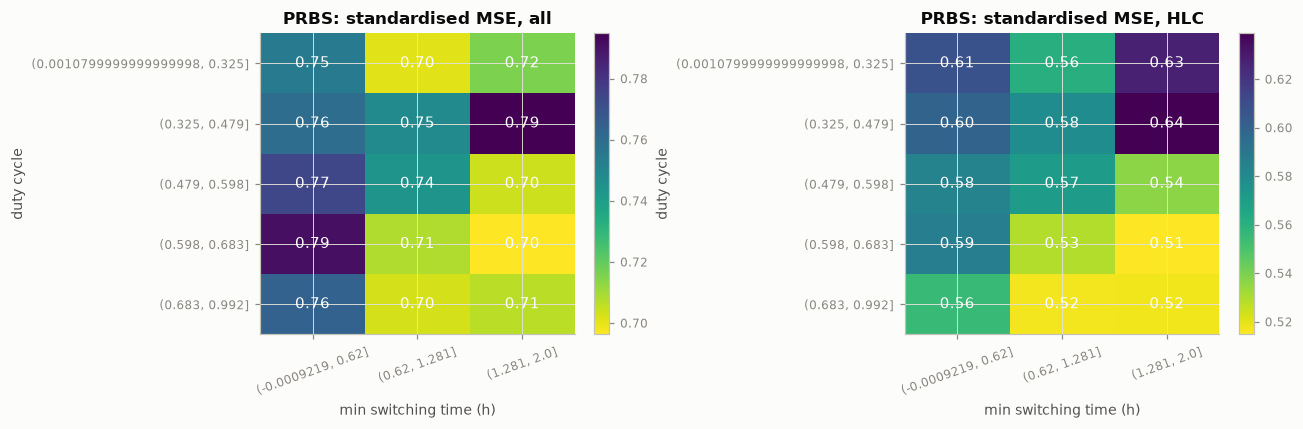

In [4]:
best_label = min(results, key=lambda k: results[k]["loss"])
r = results[best_label]
se = (r["z_pred"] - r["z_true"]).pow(2).numpy()
err = pd.DataFrame(se, columns=names)
err["all"] = err[list(names)].mean(axis=1)
err["regime"] = regime
print(f"best model: {best_label}")
display(err.groupby("regime")[["all", *names]].mean().round(3))

prbs = regime == "PRBS"
grid = pd.DataFrame({
    "duty cycle": pd.qcut(duty.numpy()[prbs], 5),
    "min switching time (h)": pd.qcut(t_min[prbs], 3),
    "all": err.loc[prbs, "all"].values,
    "HLC": err.loc[prbs, "HLC"].values,
})
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["all", "HLC"]):
    table = grid.pivot_table(index="duty cycle", columns="min switching time (h)", values=col, aggfunc="mean", observed=True)
    display(table.round(3).rename_axis(index=f"{col}: duty cycle"))
    im = ax.imshow(table.values, cmap="viridis_r", aspect="auto")
    ax.set_xticks(range(table.shape[1]), [str(c) for c in table.columns], rotation=20)
    ax.set_yticks(range(table.shape[0]), [str(i) for i in table.index])
    ax.set(xlabel="min switching time (h)", ylabel="duty cycle", title=f"PRBS: standardised MSE, {col}")
    for (i, j), v in np.ndenumerate(table.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="w")
    fig.colorbar(im, ax=ax)
fig.tight_layout()

## 3. Uncertainty

The β-NLL model predicts a standard deviation `σ` per target (in the standardised space).

* **Calibration**: share of validation simulations whose true value falls within `±1.645σ`
  (nominal 90 %) and `±1.96σ` (nominal 95 %).
* **Informativeness**: rank correlation between `σ` and the actual absolute error.
* **Conformal intervals** (normalised split conformal): on the calibration half, the 95 %
  quantile `q` of `|error| / σ`; the interval `prediction ± q σ` then has ≥ 95 % coverage on new
  data. Checked on the other half, with widths in physical units.

In [5]:
r = results["Gaussian β-NLL"]
prep = r["prep"]
sigma, z_err = r["pred_std_z"], (r["z_pred"] - r["z_true"])
ratio = (z_err.abs() / sigma)
rank = lambda a: a.argsort().argsort().double()
calib = {}
for j, n in enumerate(names):
    rho = torch.corrcoef(torch.stack([rank(sigma[:, j]), rank(z_err[:, j].abs())]))[0, 1]
    q = torch.quantile(ratio[half, j], 0.95)
    lo = prep.from_standardized(r["z_pred"] - q * sigma)[~half, j]
    hi = prep.from_standardized(r["z_pred"] + q * sigma)[~half, j]
    true = prep.from_standardized(r["z_true"])[~half, j]
    calib[n] = {
        "coverage ±1.645σ (90 %)": float((ratio[:, j] <= 1.645).double().mean()),
        "coverage ±1.96σ (95 %)": float((ratio[:, j] <= 1.96).double().mean()),
        "Spearman(σ, |error|)": float(rho),
        "conformal q": float(q),
        "conformal 95 % coverage (held-out half)": float(((true >= lo) & (true <= hi)).double().mean()),
        "median interval width": float((hi - lo).median()),
        "unit": "W/K" if n.startswith("HLC") else "h",
    }
display(pd.DataFrame(calib).T)

,coverage ±1.645σ (90 %),coverage ±1.96σ (95 %),"Spearman(σ, |error|)",conformal q,conformal 95 % coverage (held-out half),median interval width,unit
HLC,0.919,0.966,0.163,1.826,0.95,92.441,W/K
HLC_mit,0.886,0.944,0.162,2.0,0.949,86.946,W/K
HLC_ext,0.896,0.948,0.087,1.97,0.948,50.585,W/K
tau_b,0.9,0.951,0.038,1.947,0.95,36.102,h
tau_n,0.9,0.952,0.068,1.943,0.95,6.549,h
tau_inf,0.9,0.951,0.029,1.951,0.95,27.097,h


In [6]:
# Interval width by regime: the intervals adapt to how informative the test was.
widths = {}
for j, n in enumerate(names):
    q = calib[n]["conformal q"]
    w = (prep.from_standardized(r["z_pred"] + q * sigma) - prep.from_standardized(r["z_pred"] - q * sigma))[:, j]
    widths[n] = pd.Series(w.numpy()).groupby(regime).median()
display(pd.DataFrame(widths).round(1).rename_axis("median 95 % interval width"))

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
median 95 % interval width,,,,,,
PRBS,91.4,85.8,50.6,36.2,6.5,27.2
always on,88.1,83.3,48.0,36.0,6.4,27.0
never on,101.2,98.2,50.6,34.5,6.7,26.3


## 4. Identifiability: which combinations of targets does the curve determine?

Canonical correlation analysis between the 64-dimensional embedding that the network pools
from the curve and the 5 independent standardised targets (`HLC_mit`, `HLC_ext`, `log tau_b`,
`log tau_n`, `log tau_inf`). Each canonical pair is a combination of targets and a combination of
embedding features that are maximally correlated; the canonical correlation `ρ` says how well that
target combination is determined (`ρ²` = share of its variance explained). Fitted on the
calibration half, correlations reported on the other half.

In [7]:
def cca(x: torch.Tensor, y: torch.Tensor, eps: float = 1e-6):
    # Canonical directions for x (p) and y (q), via whitening + SVD; returns (Wx, Wy).
    x, y = x - x.mean(0), y - y.mean(0)
    def inv_sqrt(c):
        e, v = torch.linalg.eigh(c + eps * torch.eye(len(c), dtype=c.dtype))
        return v @ torch.diag(e.clamp_min(eps).rsqrt()) @ v.T
    n = len(x)
    cxx_is, cyy_is = inv_sqrt(x.T @ x / n), inv_sqrt(y.T @ y / n)
    u, s, vt = torch.linalg.svd(cxx_is @ (x.T @ y / n) @ cyy_is)
    k = min(x.shape[1], y.shape[1])
    return cxx_is @ u[:, :k], cyy_is @ vt.T[:, :k]


cols = ["HLC_mit", "HLC_ext", "log tau_b", "log tau_n", "log tau_inf"]
r = results[best_label]
emb, ztar = r["embedding"].double(), r["z_true"][:, 1:].double()  # drop HLC (= mit + ext)
wx, wy = cca(emb[half], ztar[half])
a, b = (emb[~half] - emb[half].mean(0)) @ wx, (ztar[~half] - ztar[half].mean(0)) @ wy
rho = [float(torch.corrcoef(torch.stack([a[:, i], b[:, i]]))[0, 1]) for i in range(len(cols))]
directions = pd.DataFrame((wy / wy.norm(dim=0)).numpy(), index=cols, columns=[f"pair {i + 1}" for i in range(len(cols))])
display(pd.DataFrame({"canonical correlation ρ (held-out)": rho, "ρ² (variance explained)": np.square(rho)},
                     index=directions.columns).round(3))
display(directions.round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))

,canonical correlation ρ (held-out),ρ² (variance explained)
pair 1,0.971,0.942
pair 2,0.660,0.436
pair 3,0.521,0.272
pair 4,0.157,0.025
pair 5,0.025,0.001


,pair 1,pair 2,pair 3,pair 4,pair 5
HLC_mit,-0.610000,0.000000,-0.250000,-0.080000,-0.090000
HLC_ext,-0.390000,-0.440000,-0.030000,0.150000,-0.030000
log tau_b,-0.060000,0.230000,-0.860000,0.630000,-0.590000
log tau_n,-0.680000,0.540000,0.180000,0.270000,-0.150000
log tau_inf,0.100000,-0.680000,0.410000,-0.710000,0.790000


### 4.1 The best-determined combination is an effective heat capacity

The first canonical direction weights the heat-loss coefficients and `log tau_n` with the same
sign. Since a time constant is a capacity over a conductance (`tau ~ C / H`), this is
`log(HLC x tau_n) ~ log C_n`: the heat capacity reached by the building over the test's time scale.
Direct check: R² (validation) of the model's implied `HLC x tau_n` and `HLC x tau_inf`, against that
of the factors alone (all in log space).

,"R² (log space, validation)"
HLC,0.420
tau_n,0.258
C_n = HLC x tau_n (kWh/K),0.840
tau_inf,0.101
C_inf = HLC x tau_inf (kWh/K),0.373
tau_n / tau_inf,0.246


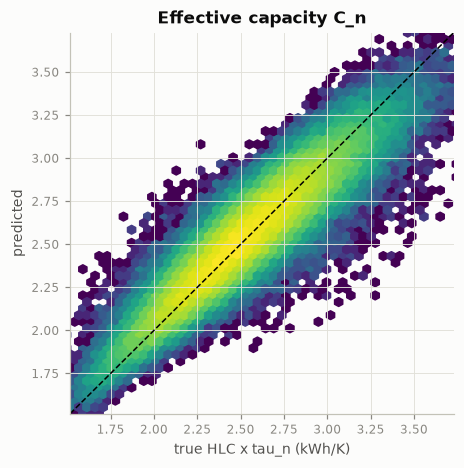

In [8]:
pred, true = r["pred"].double(), r["target"].double()
col = {n: i for i, n in enumerate(names)}
def r2_log(f):
    p, t = f(pred).log(), f(true).log()
    return float(1 - (p - t).pow(2).mean() / t.var())
checks = {
    "HLC": lambda y: y[:, col["HLC"]],
    "tau_n": lambda y: y[:, col["tau_n"]],
    "C_n = HLC x tau_n (kWh/K)": lambda y: y[:, col["HLC"]] * y[:, col["tau_n"]] / 1000,
    "tau_inf": lambda y: y[:, col["tau_inf"]],
    "C_inf = HLC x tau_inf (kWh/K)": lambda y: y[:, col["HLC"]] * y[:, col["tau_inf"]] / 1000,
    "tau_n / tau_inf": lambda y: y[:, col["tau_n"]] / y[:, col["tau_inf"]],
}
display(pd.Series({k: r2_log(f) for k, f in checks.items()}, name="R² (log space, validation)").round(3).to_frame())
c_true = checks["C_n = HLC x tau_n (kWh/K)"](true)
c_pred = checks["C_n = HLC x tau_n (kWh/K)"](pred)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.hexbin(c_true.numpy(), c_pred.numpy(), gridsize=60, bins="log", mincnt=1)
lim = [float(c_true.quantile(0.001)), float(c_true.quantile(0.999))]
ax.plot(lim, lim, "k--", lw=1)
ax.set(xlim=lim, ylim=lim, xlabel="true HLC x tau_n (kWh/K)", ylabel="predicted", title="Effective capacity C_n");

## 5. Findings

Models: TCN + attention on the full training set (800k), 30 epochs, cosine learning rate.
`final_tcn_mse` (MSE loss, precise BatchNorm before each validation) and `final_tcn_gaussian_nll`
(β-NLL loss, mean and variance per target).

**1. Point accuracy (validation, 100k).** Standardised MSE **0.734** for both models: predicting a
variance costs nothing on the means.

| Target | MAPE | P95 APE | R² |
|---|---|---|---|
| HLC | 8.3 % | 21.0 % | 0.42 |
| HLC_ext | 9.6 % | 24.2 % | 0.42 |
| HLC_mit | 15.9 % | 42.4 % | 0.27 |
| tau_n | 12.2 % | 29.6 % | 0.24 |
| tau_b | 14.9 % | 36.6 % | 0.11 |
| tau_inf | 17.9 % | 44.1 % | 0.09 |

**2. Which tests are informative.**

* Without heating, HLC is barely identifiable (standardised MSE 0.76 vs 0.51 with the heater always
  on and 0.56 for PRBS): no injected energy, no heat-loss measurement. The time constants are not
  worse without heating, they come from the free response.
* Within PRBS, HLC is best measured with a **high duty cycle (> 0.6) and switching steps of at
  least ~40 min** (MSE 0.52–0.54 vs 0.58–0.64 for low duty cycles). Fast switching (< 0.6 h) is the
  worst setting overall (0.75–0.79 vs 0.70–0.71 for the best cells): more energy and lower
  frequencies make the test more informative, consistent with the physics.

**3. Uncertainty.**

* The predicted σ is **well calibrated** (90 % nominal: 0.89–0.92 observed; 95 %: 0.94–0.97) but
  only **weakly informative per sample** (Spearman(σ, |error|) = 0.16 for HLC and HLC_mit, below
  0.1 for the others): the error is dominated by what the 8 h test cannot see, roughly the same for
  every test.
* **Conformal intervals** reach 95 % coverage on held-out data (0.948–0.950). Median widths: HLC
  92 W/K (about ±20 %), HLC_ext 51 W/K, HLC_mit 87 W/K, tau_n 6.5 h, tau_b 36 h, tau_inf 27 h.
  They are narrower for heated tests (HLC: 88 W/K always on vs 101 W/K never on).

**4. Identifiability: the 8 h test measures an effective heat capacity.**

* Canonical correlations between the learned embedding and the 5 independent targets (held-out):
  **0.97, 0.66, 0.52, 0.16, 0.03**. One combination of targets is almost fully determined, two are
  partly determined, two are not determined at all.
* The first combination weights `HLC_mit`, `HLC_ext` and `log tau_n` with the same sign:
  `log(HLC x tau_n)`, i.e. the **effective heat capacity `C_n = HLC x tau_n`** reached over the test's
  time scale. The model predicts it with **R² = 0.84** (log space), against 0.42 for HLC and 0.26
  for tau_n separately. Likewise `C_inf = HLC x tau_inf`: R² 0.37 against 0.10 for tau_inf.
* So the curve measures **how much heat the building stores** over a few hours very well; what it
  cannot do is **split** that between "loses heat fast" (HLC) and "responds slowly" (tau). The errors
  on HLC and tau_n are therefore strongly anti-correlated.
* The second pair (ρ = 0.66) mainly contrasts `log tau_n` with `log tau_inf` and `HLC_ext`; the third
  (0.52) is mostly `log tau_b`. The last two directions carry essentially no information from the test.

**Implications.**

* The performance plateau (about 0.73) is an identifiability limit of an 8 h test, not a modelling
  failure: one effective capacity is measured well, the split into the six indicators much less
  (model-free confirmation in notebook 06).
* For coEnergy: report `C_n` (well measured) next to the six indicators with their calibrated
  intervals, and favour high-energy PRBS protocols with steps of about an hour or more.